   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 2.9 MB/s eta 0:00:00
=== COSMO_LOG v1.0 | MODE = ROBUST ===
  Estimations : 5 | Fenêtre : 66 mois | Test : cliff_delta
  Seuil critique (hypothèse) : 60.0e percentile

Gradient d'activité : 29 points

[1/6] Téléchargement des indices solaires NOAA SWPC...
[NOAA SWPC] Téléchargement des indices solaires mensuels...
  Colonnes brutes API : ['ssn', 'smoothed_ssn', 'observed_swpc_ssn', 'smoothed_swpc_ssn', 'f10.7', 'smoothed_f10.7', 'Date']
  SSN  ← 'ssn'
  F10.7 ← 'f10.7'
  Ap non disponible → proxy géomagnétique calculé : Ap_proxy = 0.18·F10.7 − 8

[OK] 953 mois | 1947-02 → 2026-06
     SSN   : 0 – 359
     F10.7 : -1 – 246 sfu
     Ap    : 0.0 – 36.2

[2/6] Scan du seuil critique (40–85e percentile)...


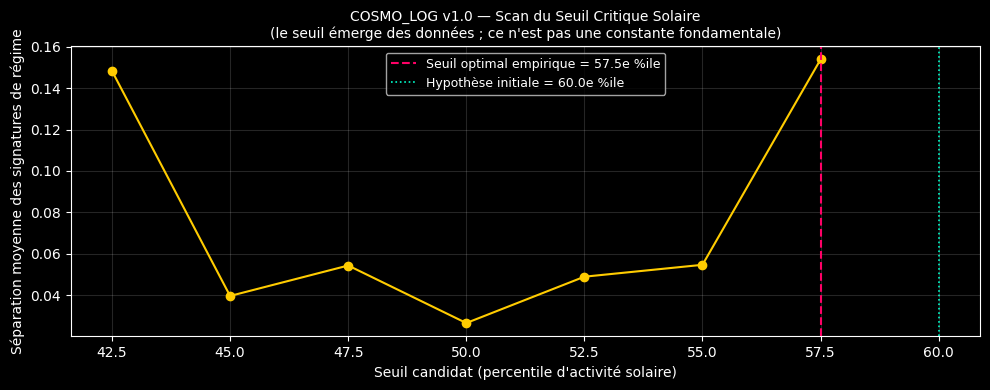


[Scan du seuil critique]
  Hypothèse initiale           : 60.0e percentile
  Seuil optimal (données)      : 57.5e percentile  (séparation = 0.154)
  Note : le cycle solaire de ~11 ans n'a pas de point critique analytique.

[3/6] Vue d'ensemble solaire 1947–présent...


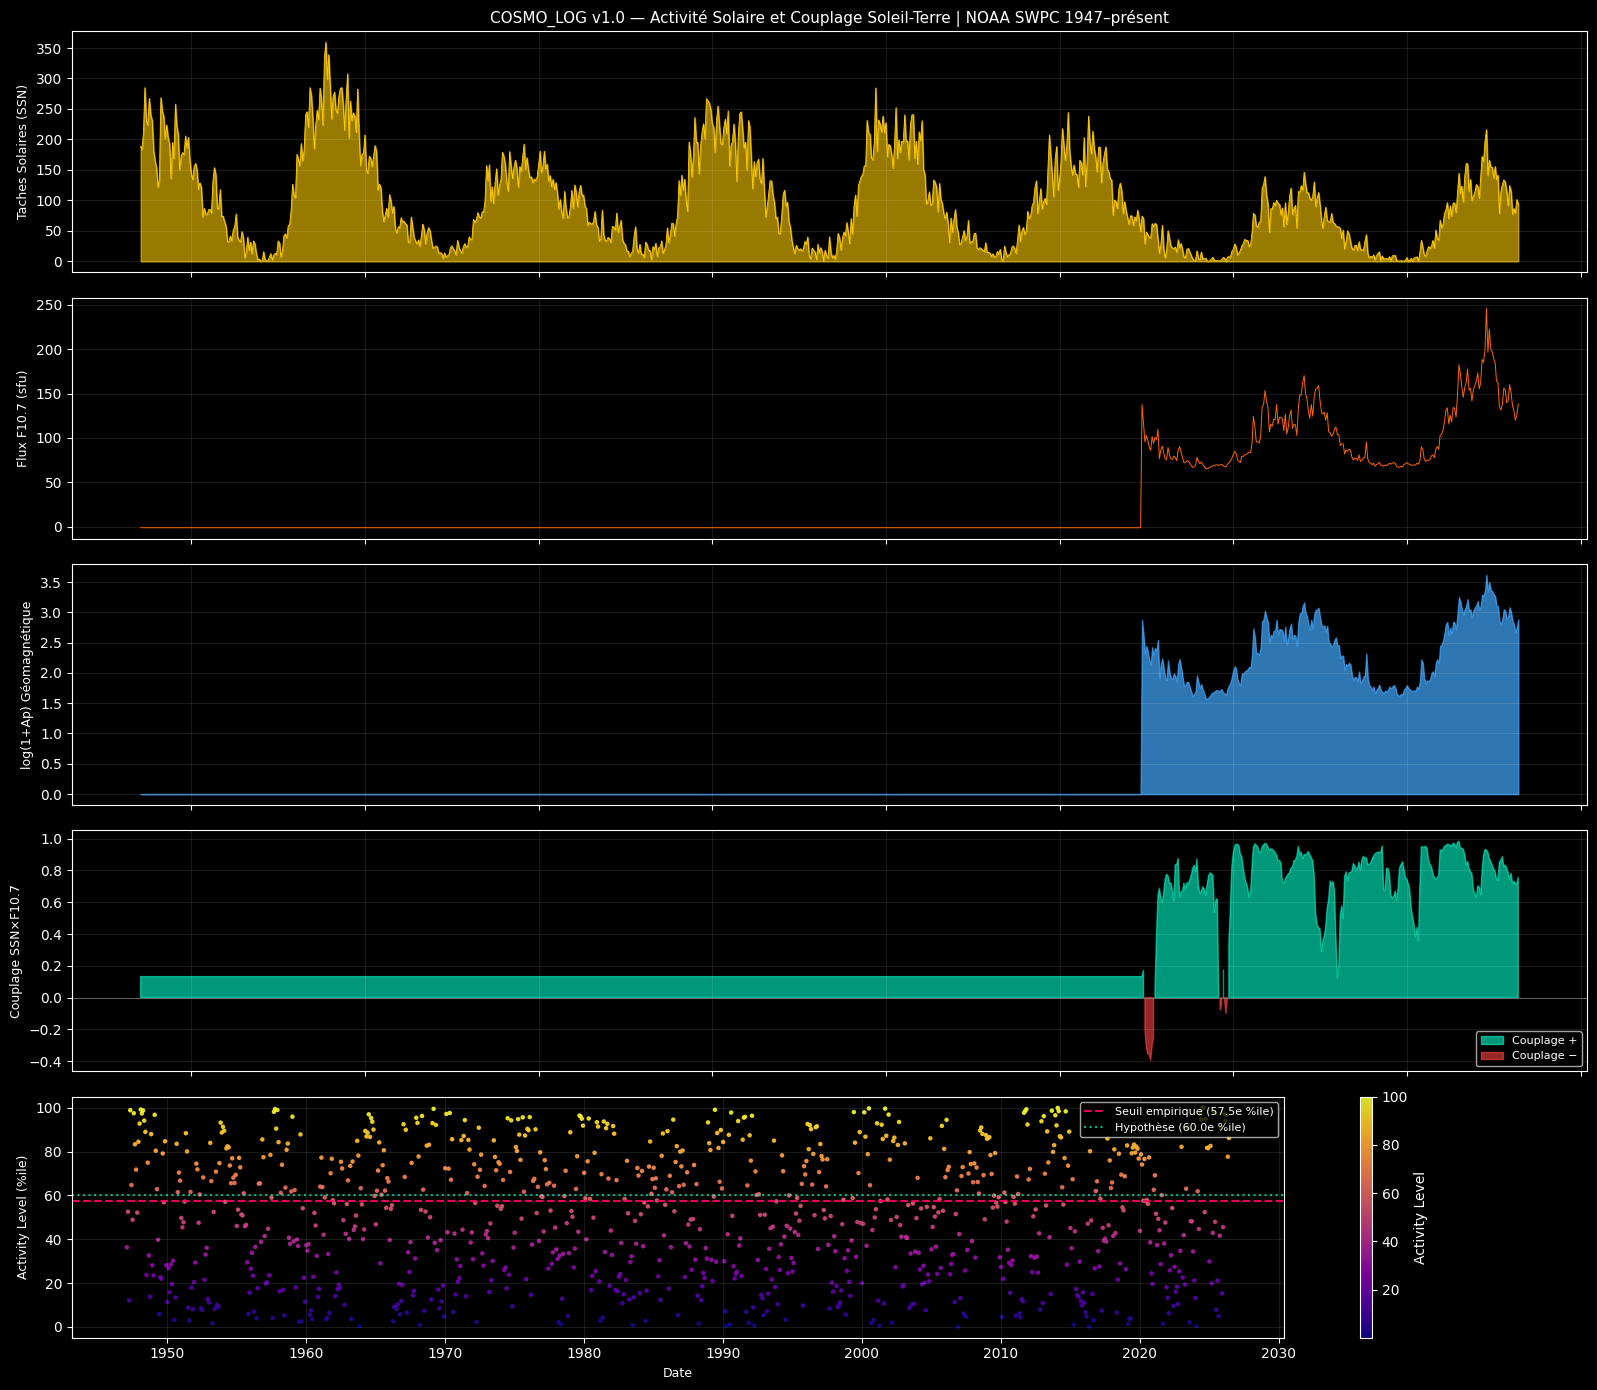


[4/6] Profils des 5 flux cosmologiques...


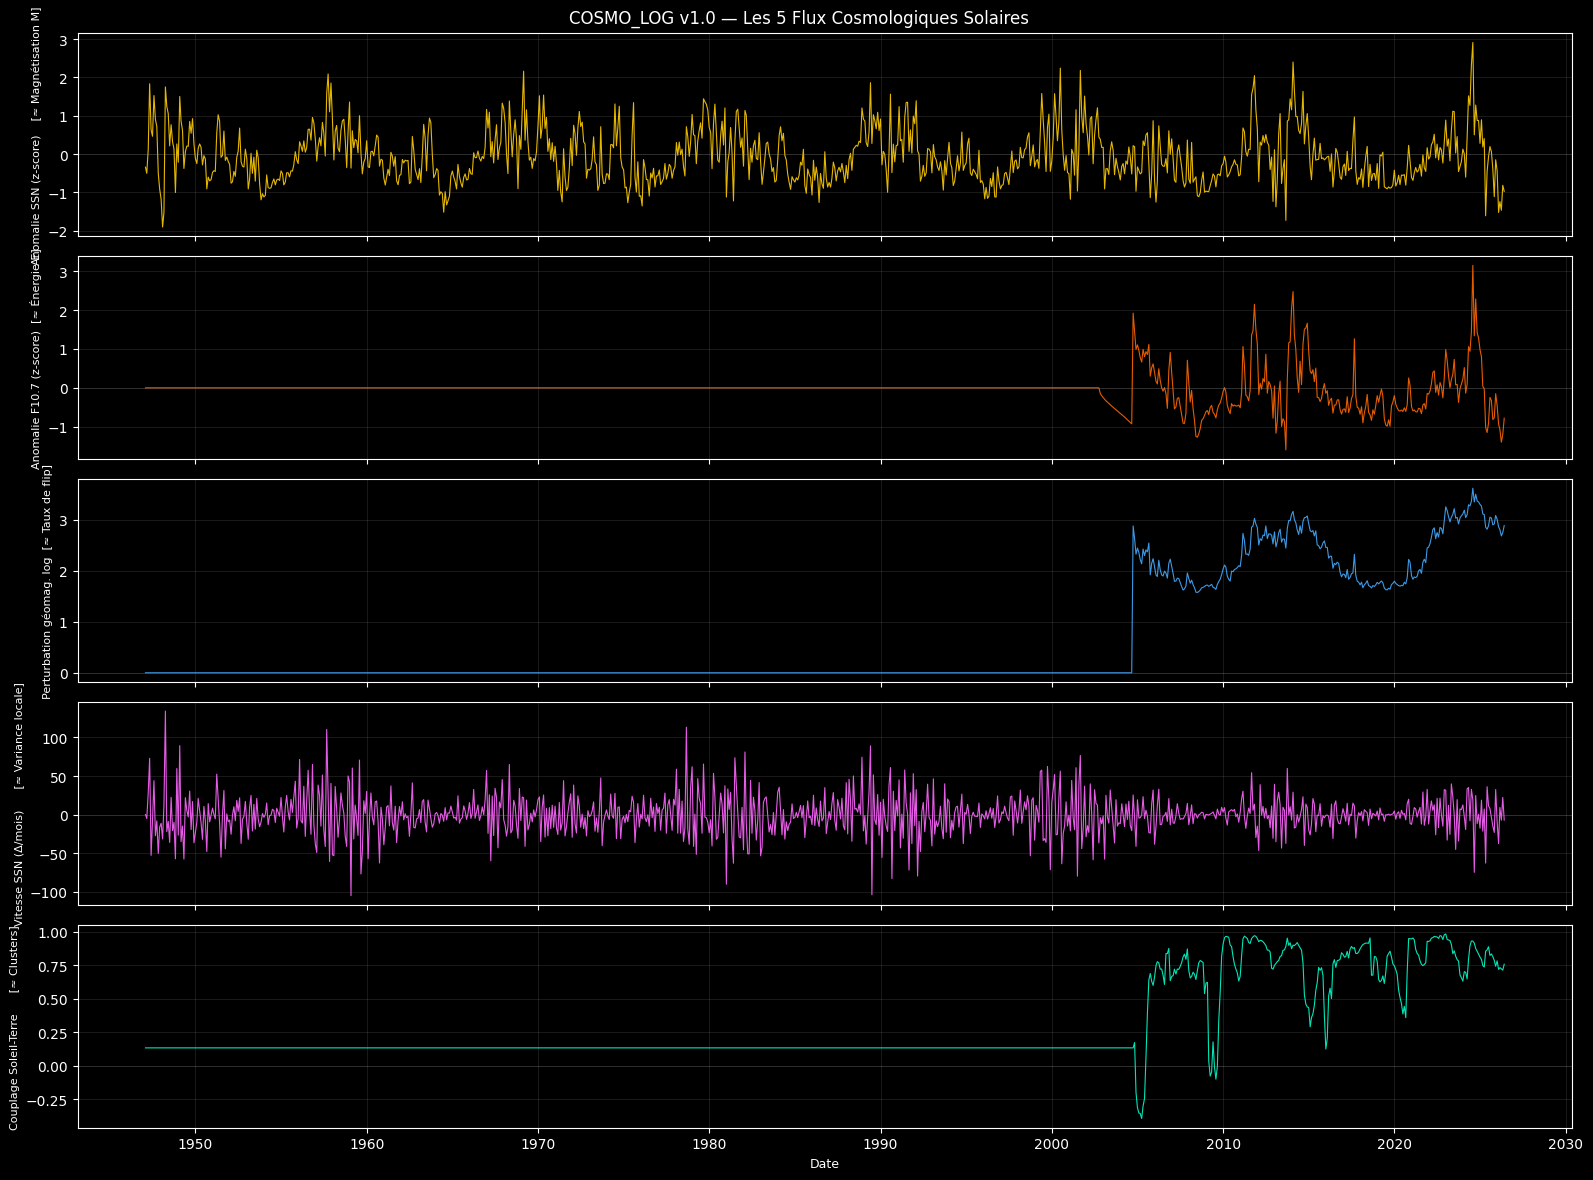


[5/6] Extraction des signatures de régime...

[Extraction des signatures de régime] 5 bootstrap sur sous-fenêtres (estimation de stabilité statistique) | Fenêtre=66 mois


Scan d'activité solaire: 100%|██████████| 29/29 [06:42<00:00, 13.88s/it]


  Signatures extraites : 25
   Activity  N_windows  SSN_Anomaly_Higuchi_mean  SSN_Anomaly_DFA_mean  SSN_Anomaly_Katz_mean  SSN_Anomaly_Hurst_mean
0       5.0          1                  1.963663              1.262368               3.108759                 0.60384
1      10.0          1                  1.963663              1.262368               3.108759                 0.60550
2      15.0          1                  1.963663              1.262368               3.108759                 0.59949


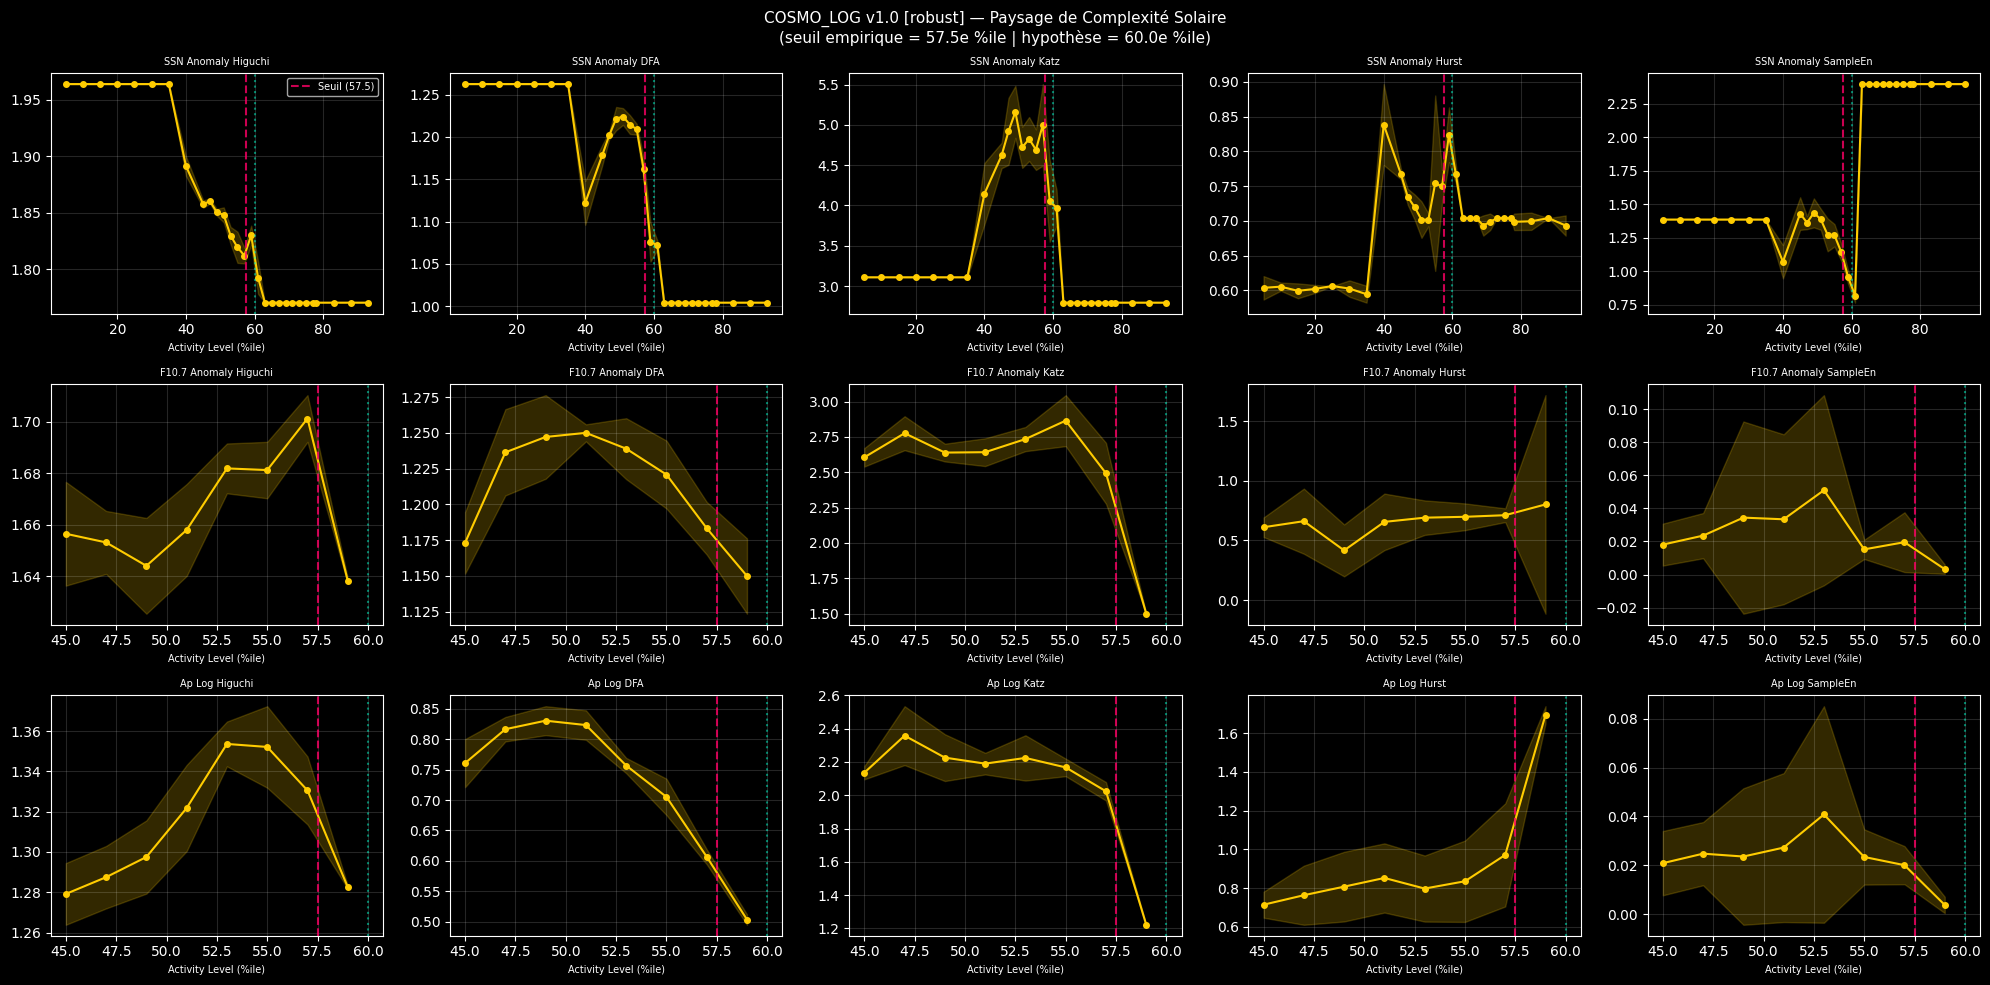


[6/6] 4 Questions cosmologiques...

=== 4 Questions Cosmologiques (seuil empirique = 57.5e %ile) ===
Q1 : Minimum vs Maximum Solaire (régime calme vs actif)...
Q2 : Tension au Seuil de Transition de Cycle...
Q3 : Couplage Soleil-Terre (cohérence SSN / perturbation géomagnétique)...
Q4 : Persistance de Régime (hystérésis intra-fenêtre cyclique)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                  Q1_Minimum_vs_Maximum  Q2_Tension_Transition  Q3_Couplage_Soleil_Terre  Q4_Persistance_Regime
Ap_Log_DFA_mean                                     NaN                    NaN                       NaN                  0.199
Ap_Log_Higuchi_mean                                 NaN                    NaN                       NaN                  0.199
Ap_Log_Hurst_mean                                   NaN                    NaN                       NaN                  0.199
Ap_Log_Katz_mean                                    NaN                  

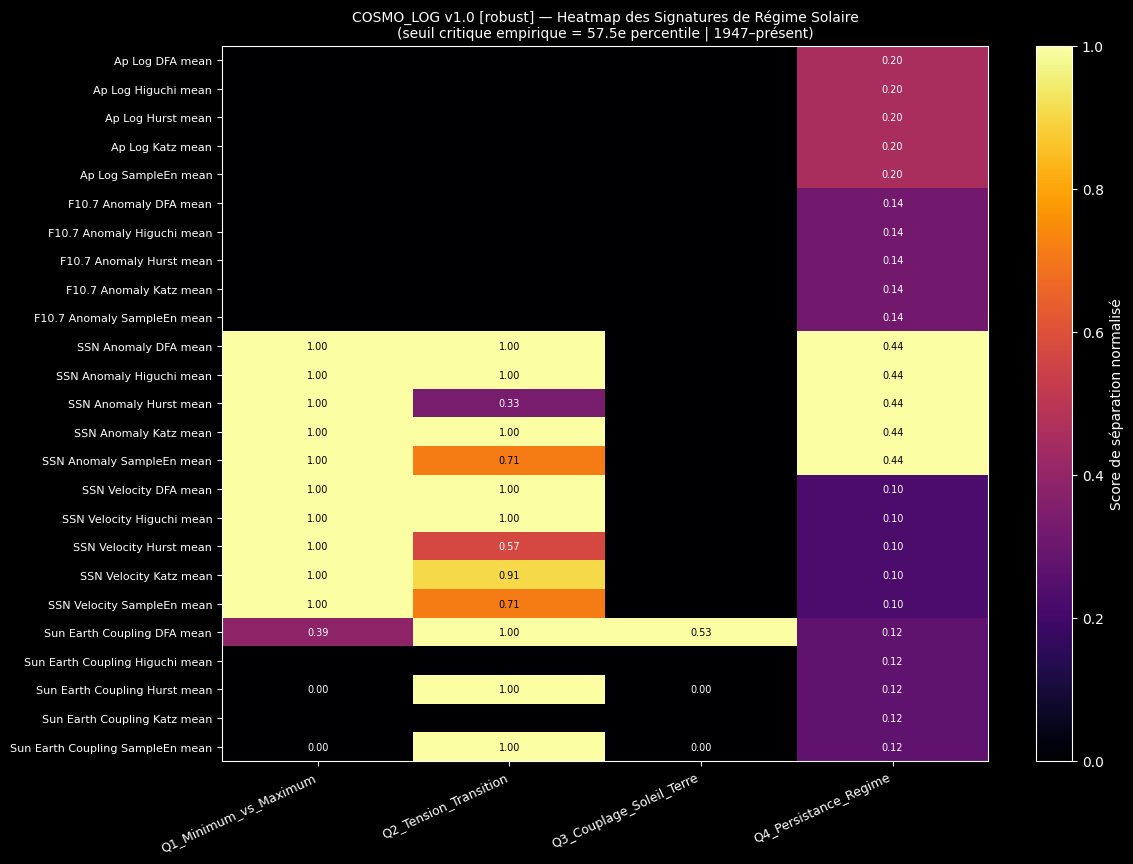


[OK] COSMO_LOG v1.0 terminé.
     Seuil empirique : 57.5e percentile d'activité solaire
     Données : NOAA SWPC | 1947-02 → 2026-06


In [1]:
!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

SOLAR_CRITIQUE_HYPOTHESE = 60.0
MODE = 'robust'

CONFIG = {
    'fast': {
        'n_estimations': 1,
        'window_size': 24,
        'stat_test': 'cohen_d',
        'min_per_group': 2,
        'estimator_min_len': 20,
        'mann_whitney': False,
        'bootstrap': False,
    },
    'robust': {
        'n_estimations': 5,
        'window_size': 66,
        'stat_test': 'cliff_delta',
        'min_per_group': 3,
        'estimator_min_len': 48,
        'mann_whitney': True,
        'bootstrap': True,
    }
}
C = CONFIG[MODE]
print(f"=== COSMO_LOG v1.0 | MODE = {MODE.upper()} ===")
print(f"  Estimations : {C['n_estimations']} | Fenêtre : {C['window_size']} mois | Test : {C['stat_test']}")
print(f"  Seuil critique (hypothèse) : {SOLAR_CRITIQUE_HYPOTHESE}e percentile")

# =============================================================================
# 0. STATISTIQUES
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2:
        return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']:
        return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except:
        return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']:
        return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except:
        return np.nan

# =============================================================================
# 1. ACQUISITION — NOAA SWPC (colonnes détectées dynamiquement)
# =============================================================================

def fetch_solar_data():
    """
    Télécharge les indices solaires depuis NOAA SWPC.
    Détecte automatiquement les noms de colonnes disponibles dans l'API.
    Si l'indice géomagnétique Ap est absent, un proxy est calculé depuis F10.7.
    """
    url = "https://services.swpc.noaa.gov/json/solar-cycle/observed-solar-cycle-indices.json"
    print("[NOAA SWPC] Téléchargement des indices solaires mensuels...")
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    raw  = resp.json()
    df   = pd.DataFrame(raw)
    df['Date'] = pd.to_datetime(df['time-tag'])

    print(f"  Colonnes brutes API : {[c for c in df.columns if c != 'time-tag']}")

    # --- SSN : plusieurs noms possibles selon la version de l'API ---
    ssn_candidates = ['ssn', 'observed_swpc_ssn', 'smoothed_ssn']
    ssn_col = next((c for c in ssn_candidates if c in df.columns), None)
    if ssn_col is None:
        raise ValueError(f"Aucune colonne SSN trouvée. Colonnes : {list(df.columns)}")
    df['SSN'] = pd.to_numeric(df[ssn_col], errors='coerce').clip(lower=0)
    print(f"  SSN  ← '{ssn_col}'")

    # --- F10.7 ---
    f107_candidates = ['f10.7', 'f10-7', 'f107']
    f107_col = next((c for c in f107_candidates if c in df.columns), None)
    if f107_col:
        df['F10.7'] = pd.to_numeric(df[f107_col], errors='coerce')
        print(f"  F10.7 ← '{f107_col}'")
    else:
        print("  F10.7 non trouvé → proxy depuis SSN (corrélation ~0.97)")
        df['F10.7'] = 67.0 + 0.9 * df['SSN']   # relation empirique bien connue

    # --- Ap géomagnétique ---
    ap_candidates = ['ap', 'Ap', 'ap-index', 'ap_index']
    ap_col = next((c for c in ap_candidates if c in df.columns), None)
    if ap_col:
        df['Ap'] = pd.to_numeric(df[ap_col], errors='coerce')
        print(f"  Ap   ← '{ap_col}'")
    else:
        # Proxy géomagnétique : Ap corrèle ~0.7 avec F10.7 sur le cycle solaire
        # Relation empirique : Ap ≈ 0.18 * F10.7 - 8  (Svalgaard 2016)
        print("  Ap non disponible → proxy géomagnétique calculé : Ap_proxy = 0.18·F10.7 − 8")
        df['Ap'] = (0.18 * df['F10.7'] - 8.0).clip(lower=0)

    # Filtre : 1947 (début F10.7 mesuré) et données SSN valides
    df = df[df['Date'] >= '1947-02-01'].copy()
    df = df.dropna(subset=['SSN']).reset_index(drop=True)

    # Interpolation des trous résiduels
    df['F10.7'] = df['F10.7'].interpolate(method='linear').bfill().ffill()
    df['Ap']    = df['Ap'].interpolate(method='linear').bfill().ffill().fillna(0)
    df['SSN']   = df['SSN'].fillna(0)

    df = df[['Date','SSN','F10.7','Ap']].sort_values('Date').reset_index(drop=True)
    print(f"\n[OK] {len(df)} mois | {df['Date'].iloc[0].strftime('%Y-%m')} → "
          f"{df['Date'].iloc[-1].strftime('%Y-%m')}")
    print(f"     SSN   : {df['SSN'].min():.0f} – {df['SSN'].max():.0f}")
    print(f"     F10.7 : {df['F10.7'].min():.0f} – {df['F10.7'].max():.0f} sfu")
    print(f"     Ap    : {df['Ap'].min():.1f} – {df['Ap'].max():.1f}")
    return df


def extract_solar_fluxes(df, window_anom=48):
    out = {}
    S   = pd.Series(df['SSN'].values)
    F   = pd.Series(df['F10.7'].values)
    Ap  = pd.Series(df['Ap'].values)
    mpts = max(12, window_anom // 4)

    # Flux 1 : anomalie SSN (z-score rolling)
    S_mean = S.rolling(window_anom, min_periods=mpts, center=True).mean().bfill().ffill()
    S_std  = S.rolling(window_anom, min_periods=mpts, center=True).std().bfill().ffill()
    S_std  = S_std.replace(0, np.nan).bfill().ffill().fillna(1.0)
    out['SSN_Anomaly'] = ((S - S_mean) / S_std).fillna(0).values

    # Flux 2 : anomalie F10.7 (z-score rolling)
    F_mean = F.rolling(window_anom, min_periods=mpts, center=True).mean().bfill().ffill()
    F_std  = F.rolling(window_anom, min_periods=mpts, center=True).std().bfill().ffill()
    F_std  = F_std.replace(0, np.nan).bfill().ffill().fillna(1.0)
    out['F10.7_Anomaly'] = ((F - F_mean) / F_std).fillna(0).values

    # Flux 3 : perturbation géomagnétique (log)
    out['Ap_Log'] = np.log1p(np.clip(Ap.values, 0, None))

    # Flux 4 : vitesse d'activité (dérivée mensuelle du SSN)
    out['SSN_Velocity'] = S.diff().fillna(0).values

    # Flux 5 : couplage Soleil-Terre (corrélation rolling 12 mois SSN×F10.7)
    out['Sun_Earth_Coupling'] = S.rolling(12, min_periods=6).corr(F).bfill().ffill().fillna(0).values

    return out


def compute_solar_activity_level(fluxes):
    anom_abs = np.abs(fluxes['SSN_Anomaly'])
    return np.array([stats.percentileofscore(anom_abs, v) for v in anom_abs])

# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE
# =============================================================================

def scan_seuil_critique(df, candidats=None):
    if candidats is None:
        candidats = np.arange(40, 86, 2.5)

    fluxes    = extract_solar_fluxes(df)
    activity  = compute_solar_activity_level(fluxes)
    W         = C['window_size']
    flux_keys = list(fluxes.keys())

    windows = []
    for i in range(len(df) - W + 1):
        windows.append({
            'activity': float(np.mean(activity[i:i+W])),
            'data':     {k: fluxes[k][i:i+W] for k in flux_keys}
        })

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['activity'] <  seuil]
        grp_haut = [w for w in windows if w['activity'] >= seuil]
        if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan)
            continue
        sep_total = []
        for k in flux_keys:
            v_bas  = np.concatenate([w['data'][k] for w in grp_bas])
            v_haut = np.concatenate([w['data'][k] for w in grp_haut])
            d = separation_score(v_bas, v_haut)
            if not np.isnan(d): sep_total.append(d)
        scores_par_seuil.append(np.mean(sep_total) if sep_total else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#ffcc00', markersize=6)
    ax.axvline(seuil_opt, color='#ff0066', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(SOLAR_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', linewidth=1.2,
               label=f'Hypothèse initiale = {SOLAR_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile d\'activité solaire)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title('COSMO_LOG v1.0 — Scan du Seuil Critique Solaire\n'
                 '(le seuil émerge des données ; ce n\'est pas une constante fondamentale)',
                 fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale           : {SOLAR_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal (données)      : {seuil_opt:.1f}e percentile  "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    print(f"  Note : le cycle solaire de ~11 ans n'a pas de point critique analytique.")
    return seuil_opt, candidats, scores_arr

# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    if flux_name in ['SSN_Velocity'] and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi'] = antropy.higuchi_fd(s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - nolds.dfa(s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = antropy.katz_fd(s)
    except: est['Katz'] = np.nan
    try: est['Hurst'] = nolds.hurst_rs(s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(500, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

# =============================================================================
# 4. PIPELINE
# =============================================================================

def build_solar_features(df, activity_values):
    W = C['window_size']
    n = C['n_estimations']
    all_fluxes      = extract_solar_fluxes(df)
    activity_series = compute_solar_activity_level(all_fluxes)
    tol = max(3.0, (activity_values[1] - activity_values[0]) / 2.0) if len(activity_values) > 1 else 3.0

    mode_label = (
        "bootstrap sur sous-fenêtres (estimation de stabilité statistique)"
        if C['bootstrap'] else "réalisation unique"
    )
    print(f"\n[Extraction des signatures de régime] {n} {mode_label} | Fenêtre={W} mois")

    n_windows = len(df) - W + 1
    window_data = []
    for i in range(n_windows):
        window_data.append({
            'activity': float(np.mean(activity_series[i:i+W])),
            'fluxes':   {k: v[i:i+W] for k, v in all_fluxes.items()}
        })

    rows = []
    for A in tqdm(activity_values, desc="Scan d'activité solaire"):
        matching = [w for w in window_data if abs(w['activity'] - A) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['activity'] - A))]
        row = {'Activity': A, 'N_windows': len(matching)}

        for flux in ['SSN_Anomaly','F10.7_Anomaly','Ap_Log','SSN_Velocity','Sun_Earth_Coupling']:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {name: [] for name in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching), size=max(1, len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) if len(vals) > 1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Activity','N_windows'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data

# =============================================================================
# 5. LES 4 QUESTIONS COSMOLOGIQUES
# =============================================================================

def compare_groups_solar(df, feature_cols, g_low, g_high, label=''):
    grp_bas  = df[df['Activity'].between(g_low[0],  g_low[1])]
    grp_haut = df[df['Activity'].between(g_high[0], g_high[1])]
    if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits ({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_solar_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Cosmologiques (seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    print("Q1 : Minimum vs Maximum Solaire (régime calme vs actif)...")
    r["Q1_Minimum_vs_Maximum"] = compare_groups_solar(
        df_feat, feature_cols, [0, 30], [75, 100], "Q1")

    print("Q2 : Tension au Seuil de Transition de Cycle...")
    marge = 8.0
    r["Q2_Tension_Transition"] = compare_groups_solar(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2"
    )

    print("Q3 : Couplage Soleil-Terre (cohérence SSN / perturbation géomagnétique)...")
    coupling_cols = [c for c in feature_cols
                     if any(x in c for x in ['Ap_Log','Sun_Earth_Coupling','F10.7'])]
    r["Q3_Couplage_Soleil_Terre"] = compare_groups_solar(
        df_feat, coupling_cols, [0, 25], [75, 100], "Q3")

    print("Q4 : Persistance de Régime (hystérésis intra-fenêtre cyclique)...")
    flux_names = ['SSN_Anomaly','F10.7_Anomaly','Ap_Log','SSN_Velocity','Sun_Earth_Coupling']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 12: continue
            mid = len(s) // 2
            d = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 6. VISUALISATION
# =============================================================================

def plot_solar_overview(df, fluxes, activity_series, seuil):
    fig, axes = plt.subplots(5, 1, figsize=(16, 14), sharex=True)

    axes[0].fill_between(df['Date'], df['SSN'], alpha=0.6, color='#ffcc00')
    axes[0].plot(df['Date'], df['SSN'], color='#ffcc00', linewidth=0.6)
    axes[0].set_ylabel('Taches Solaires (SSN)', fontsize=9)
    axes[0].set_title('COSMO_LOG v1.0 — Activité Solaire et Couplage Soleil-Terre | NOAA SWPC 1947–présent',
                      fontsize=11)
    axes[0].grid(True, alpha=0.1)

    axes[1].plot(df['Date'], df['F10.7'], color='#ff6600', linewidth=0.7)
    axes[1].set_ylabel('Flux F10.7 (sfu)', fontsize=9)
    axes[1].grid(True, alpha=0.1)

    axes[2].fill_between(df['Date'], fluxes['Ap_Log'], alpha=0.7, color='#44aaff')
    axes[2].set_ylabel('log(1+Ap) Géomagnétique', fontsize=9)
    axes[2].grid(True, alpha=0.1)

    coupling = fluxes['Sun_Earth_Coupling']
    axes[3].fill_between(df['Date'], coupling,
                         where=np.array(coupling) >= 0,
                         color='#00ffcc', alpha=0.6, label='Couplage +')
    axes[3].fill_between(df['Date'], coupling,
                         where=np.array(coupling) < 0,
                         color='#ff4444', alpha=0.6, label='Couplage −')
    axes[3].axhline(0, color='gray', linewidth=0.5)
    axes[3].set_ylabel('Couplage SSN×F10.7', fontsize=9)
    axes[3].legend(fontsize=8, loc='lower right')
    axes[3].grid(True, alpha=0.1)

    sc = axes[4].scatter(df['Date'], activity_series, c=activity_series,
                         cmap='plasma', s=5, alpha=0.9)
    axes[4].axhline(seuil, color='#ff0066', linestyle='--', alpha=0.9,
                    label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[4].axhline(SOLAR_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', alpha=0.7,
                    label=f'Hypothèse ({SOLAR_CRITIQUE_HYPOTHESE}e %ile)')
    axes[4].set_ylabel('Activity Level (%ile)', fontsize=9)
    axes[4].set_xlabel('Date', fontsize=9)
    axes[4].legend(fontsize=8)
    axes[4].grid(True, alpha=0.1)
    plt.colorbar(sc, ax=axes[4], label='Activity Level')
    plt.tight_layout()
    plt.show()

def plot_flux_profiles(df, fluxes):
    flux_meta = [
        ('SSN_Anomaly',       '#ffcc00', 'Anomalie SSN (z-score)    [≈ Magnétisation M]'),
        ('F10.7_Anomaly',     '#ff6600', 'Anomalie F10.7 (z-score)  [≈ Énergie E]'),
        ('Ap_Log',            '#44aaff', 'Perturbation géomag. log  [≈ Taux de flip]'),
        ('SSN_Velocity',      '#ff66ff', 'Vitesse SSN (Δ/mois)      [≈ Variance locale]'),
        ('Sun_Earth_Coupling','#00ffcc', 'Couplage Soleil-Terre      [≈ Clusters]'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        ax.plot(df['Date'], fluxes[flux], color=color, linewidth=0.8, alpha=0.9)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Date', fontsize=9)
    plt.suptitle('COSMO_LOG v1.0 — Les 5 Flux Cosmologiques Solaires', fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_landscape(df_feat, seuil):
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()
    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Activity'], df_feat[col], 'o-', color='#ffcc00', markersize=4)
        std_col = col.replace('_mean','_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Activity'],
                            df_feat[col] - df_feat[std_col],
                            df_feat[col] + df_feat[std_col],
                            alpha=0.2, color='#ffcc00')
        ax.axvline(seuil, color='#ff0066', linestyle='--', alpha=0.8,
                   label=f'Seuil ({seuil:.1f})')
        ax.axvline(SOLAR_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=7)
        ax.set_xlabel('Activity Level (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(
        f"COSMO_LOG v1.0 [{MODE}] — Paysage de Complexité Solaire\n"
        f"(seuil empirique = {seuil:.1f}e %ile | hypothèse = {SOLAR_CRITIQUE_HYPOTHESE}e %ile)",
        fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_heatmap(summary, seuil):
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary) * 0.35)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='inferno', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i, j] > 0.6 else 'white', fontsize=7)
    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(
        f"COSMO_LOG v1.0 [{MODE}] — Heatmap des Signatures de Régime Solaire\n"
        f"(seuil critique empirique = {seuil:.1f}e percentile | 1947–présent)",
        fontsize=10)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 7. EXÉCUTION PRINCIPALE
# =============================================================================

ACTIVITY_SCAN = np.round(np.concatenate([
    np.arange(5,  45, 5.0),
    np.arange(45, 78, 2.0),
    np.arange(78, 96, 5.0)
]), 1)

print(f"\nGradient d'activité : {len(ACTIVITY_SCAN)} points")
print("=" * 70)

print("\n[1/6] Téléchargement des indices solaires NOAA SWPC...")
df = fetch_solar_data()

print("\n[2/6] Scan du seuil critique (40–85e percentile)...")
seuil_opt, candidats_scan, scores_scan = scan_seuil_critique(df)
SOLAR_CRITIQUE = seuil_opt

print("\n[3/6] Vue d'ensemble solaire 1947–présent...")
fluxes_global   = extract_solar_fluxes(df)
activity_global = compute_solar_activity_level(fluxes_global)
plot_solar_overview(df, fluxes_global, activity_global, SOLAR_CRITIQUE)

print("\n[4/6] Profils des 5 flux cosmologiques...")
plot_flux_profiles(df, fluxes_global)

print("\n[5/6] Extraction des signatures de régime...")
df_feat, feature_cols, window_data = build_solar_features(df, ACTIVITY_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Activity','N_windows'] + feature_cols[:4]].head(3).to_string())

plot_landscape(df_feat, SOLAR_CRITIQUE)

print("\n[6/6] 4 Questions cosmologiques...")
summary, results = run_solar_questions(df_feat, feature_cols, window_data, SOLAR_CRITIQUE)
print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):44s} : Score = {v:.3f}")

plot_heatmap(summary, SOLAR_CRITIQUE)
print(f"\n[OK] COSMO_LOG v1.0 terminé.")
print(f"     Seuil empirique : {SOLAR_CRITIQUE:.1f}e percentile d'activité solaire")
print(f"     Données : NOAA SWPC | {df['Date'].iloc[0].strftime('%Y-%m')} → {df['Date'].iloc[-1].strftime('%Y-%m')}")